# Exploratory data analysis and model evaluation

This notebook profiles `data/raw/predictive_maintainance.csv` and evaluates the model produced by
`src/pipelines/training_pipeline.py` (same cleaning, feature engineering, preprocessing, split and
Random Forest settings). Every number below is computed in the cells, not typed in.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config
from src.data_processing.load_data import load_raw_data
df = load_raw_data(ROOT / 'data/raw/predictive_maintainance.csv')
df.shape

Attempting to load raw data from: /home/claude/predictive-maintenance-construction/data/raw/predictive_maintainance.csv
Raw data loaded successfully. Shape: (10000, 12)
Column names stripped of leading/trailing whitespace.


(10000, 12)

## 1. Structure and data quality

In [2]:
summary = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique': df.nunique()})
summary

,dtype,missing,unique
Equipment_id,object,0,10000
Timestamp,object,1,1
Engine_temp,int64,0,1255
oil_pressure,float64,0,10000
Hydraulic_pressure,float64,0,82
Operating_hours,int64,0,941
Vibrations,float64,0,577
Tool_wear,int64,0,246
Fuel_rate,float64,0,9997
Ambient_temp,float64,0,93


In [3]:
print('duplicate rows:', df.duplicated().sum())
print('distinct Equipment_id values:', df['Equipment_id'].nunique(), 'of', len(df), 'rows')
print('distinct Timestamp values:', df['Timestamp'].nunique(dropna=True), '->', df['Timestamp'].dropna().unique()[:3])

duplicate rows: 0
distinct Equipment_id values: 10000 of 10000 rows
distinct Timestamp values: 1 -> ['2024-12-01']


**Finding:** every row has a different `Equipment_id` and all rows share one timestamp, so the data is a single
cross-sectional snapshot, not a time series per machine. The rolling-window features in
`feature_engineering.py` therefore have no history to use: the rolling mean falls back to the row's own value and
the rolling standard deviation is 0. They add no information on this dataset.

In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Engine_temp,10000.0,790.669,266.949,77.000,595.000,746.000,933.000,2239.000
oil_pressure,10000.0,3.296,1.020,0.004,2.512,3.166,4.040,7.266
Hydraulic_pressure,10000.0,310.006,1.484,305.700,308.800,310.100,311.100,313.800
Operating_hours,10000.0,1538.776,179.284,1168.000,1423.000,1503.000,1612.000,2886.000
Vibrations,10000.0,39.987,9.969,3.800,33.200,40.100,46.800,76.600
Tool_wear,10000.0,107.951,63.654,0.000,53.000,108.000,162.000,253.000
Fuel_rate,10000.0,6.622,2.738,0.003,4.885,6.204,7.705,21.138
Ambient_temp,10000.0,300.005,2.000,295.300,298.300,300.100,301.500,304.500
Failure_event,10000.0,0.631,0.483,0.000,0.000,1.000,1.000,1.000


In [5]:
df['Terrain_type'].value_counts(dropna=False)

Terrain_type
"plain"        2009
"alluvial"     1561
"paved"        1142
"mixed"        1117
"marshy"       1116
"sandy_wet"    1115
"rocky"         948
"sandy"         447
"sandy-wet"     447
NaN              98
Name: count, dtype: int64

**Finding:** `Terrain_type` values carry literal quote characters, `sandy_wet` and `sandy-wet` are the same
category spelled two ways, and 98 rows are missing a value (imputed with the most frequent value by the preprocessor).

## 2. Target balance and simple relationships

In [6]:
balance = df['Failure_event'].value_counts(normalize=True).rename('share')
print(balance.round(4))
print('majority-class baseline accuracy:', round(balance.max(), 4))

Failure_event
1    0.6306
0    0.3694
Name: share, dtype: float64
majority-class baseline accuracy: 0.6306


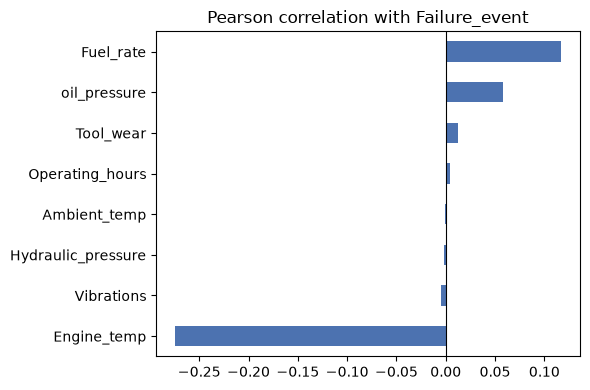

Engine_temp          -0.274
Vibrations           -0.005
Hydraulic_pressure   -0.002
Ambient_temp         -0.000
Operating_hours       0.004
Tool_wear             0.012
oil_pressure          0.058
Fuel_rate             0.117
Name: Failure_event, dtype: float64

In [7]:
num = df.select_dtypes('number')
corr = num.corr()['Failure_event'].drop('Failure_event').sort_values()
ax = corr.plot.barh(figsize=(6, 4), color='#4C72B0')
ax.set_title('Pearson correlation with Failure_event'); ax.axvline(0, color='k', lw=0.8)
plt.tight_layout(); plt.show()
corr.round(3)

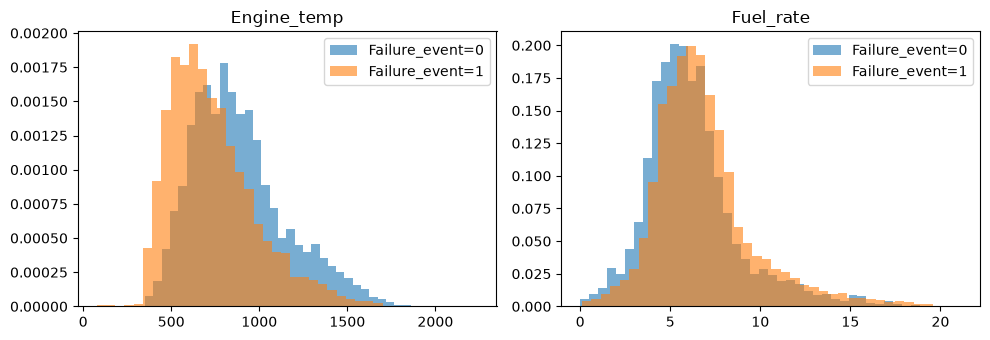

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ['Engine_temp', 'Fuel_rate']):
    for label, grp in df.groupby('Failure_event'):
        ax.hist(grp[col], bins=40, alpha=0.6, label=f'Failure_event={label}', density=True)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

In [9]:
df.groupby('Terrain_type')['Failure_event'].mean().round(3)

Terrain_type
"alluvial"     0.631
"marshy"       0.634
"mixed"        0.638
"paved"        0.628
"plain"        0.622
"rocky"        0.638
"sandy"        0.624
"sandy-wet"    0.633
"sandy_wet"    0.639
Name: Failure_event, dtype: float64

## 3. Model evaluation (same steps as the training pipeline)

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from src.data_processing.cleaning import clean_data
from src.data_processing.feature_engineering import engineer_features
from src.pipelines.training_pipeline import create_preprocessor

eng = engineer_features(clean_data(df))
y = eng[config.TARGET_COLUMN]
X = eng.drop(columns=[config.TARGET_COLUMN, config.TIMESTAMP_COLUMN, config.EQUIPMENT_ID_COLUMN])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=config.TEST_SPLIT_RATIO,
                                                    random_state=config.RANDOM_STATE, stratify=y)
pre, num_feats, cat_feats = create_preprocessor(X_train)
pre.fit(X_train)
Xtr, Xte = pre.transform(X_train), pre.transform(X_test)
model = RandomForestClassifier(n_estimators=100, random_state=config.RANDOM_STATE, n_jobs=-1).fit(Xtr, y_train)
pred, prob = model.predict(Xte), model.predict_proba(Xte)[:, 1]
metrics = {'accuracy': accuracy_score(y_test, pred), 'precision': precision_score(y_test, pred),
           'recall': recall_score(y_test, pred), 'f1': f1_score(y_test, pred), 'roc_auc': roc_auc_score(y_test, prob),
           'majority_baseline_accuracy': y_test.value_counts(normalize=True).max()}
pd.Series(metrics).round(4)


--- Starting Data Cleaning ---
Converting 'Timestamp' to datetime...
Dropped 1 rows due to invalid timestamp format.
'Timestamp' converted successfully.
Sorting data by ['Equipment_id', 'Timestamp']...
Data sorted successfully.
--- Data Cleaning Finished ---

--- Starting Feature Engineering ---
Creating interaction features...
  - Created 'temp_x_vibration'.
Interaction feature creation finished.
Creating rolling features (window=3) grouped by 'Equipment_id'...
  - Calculating for columns: ['Engine_temp', 'Vibrations']


    - Created 'Engine_temp_roll_mean_3'


    - Created 'Engine_temp_roll_std_3'


    - Created 'Vibrations_roll_mean_3'


    - Created 'Vibrations_roll_std_3'
Rolling feature creation finished.
--- Feature Engineering Finished ---
Preprocessor: Identifying numerical features: ['Engine_temp', 'oil_pressure', 'Hydraulic_pressure', 'Operating_hours', 'Vibrations', 'Tool_wear', 'Fuel_rate', 'Ambient_temp', 'temp_x_vibration', 'Engine_temp_roll_mean_3', 'Engine_temp_roll_std_3', 'Vibrations_roll_mean_3', 'Vibrations_roll_std_3']
Preprocessor: Identifying categorical features: ['Terrain_type']


accuracy                      0.6435
precision                     0.6849
recall                        0.8049
f1                            0.7401
roc_auc                       0.6676
majority_baseline_accuracy    0.6305
dtype: float64

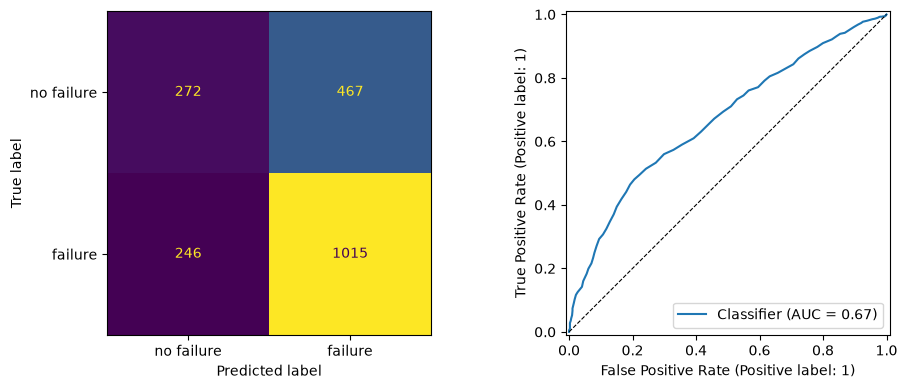

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['no failure', 'failure']).plot(ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, prob, ax=axes[1]); axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.tight_layout(); plt.show()

In [12]:
names = num_feats + list(pre.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_feats))
imp = pd.Series(model.feature_importances_, index=names).sort_values(ascending=False)
imp.head(12).round(4)

Engine_temp                0.1056
Engine_temp_roll_mean_3    0.1054
Fuel_rate                  0.1024
temp_x_vibration           0.0940
oil_pressure               0.0888
Operating_hours            0.0800
Tool_wear                  0.0785
Ambient_temp               0.0706
Vibrations                 0.0704
Vibrations_roll_mean_3     0.0696
Hydraulic_pressure         0.0677
Terrain_type_"plain"       0.0101
dtype: float64

In [13]:
# Dashboard alert rule: probability >= 0.7
alert = prob >= 0.7
print('alerts raised:', int(alert.sum()), 'of', len(prob))
print('true alerts (actual failure):', int((alert & (y_test == 1)).sum()))
print('false alerts (no failure):', int((alert & (y_test == 0)).sum()))
print('failures missed by the alert rule:', int((~alert & (y_test == 1)).sum()))

alerts raised: 727 of 2000
true alerts (actual failure): 585
false alerts (no failure): 142
failures missed by the alert rule: 676


## 4. Conclusions

* The Random Forest beats the majority-class baseline only slightly on accuracy; ROC-AUC shows weak but real
  ranking ability, driven mostly by `Engine_temp` and `Fuel_rate`.
* The rolling features are constant on this snapshot dataset, and `Terrain_type` shows almost no relationship with failure.
* Next steps: clean the terrain labels, drop the no-information features, handle class balance
  (class weights / threshold tuning), and collect repeated readings per machine so time-based features
  and a time-based split become possible.